## Creating well graphs

In [1]:
# Installation avec des versions spécifiques et compatibles
# !pip install numpy==1.24.2
# !pip install torch==2.0.0
# !pip install torchdata==0.6.0
# !pip install dgl==1.0.1 -f https://data.dgl.ai/wheels/repo.html
# !pip install pyvista==0.39.0
# !pip install networkx==3.4.2
import numpy as np
import torch
import pandas as pd
#import pyvista as pv
import networkx as nx
import glob
import time
import sys
import dgl
import dgl.data
import os
import dgl.dataloading
import tqdm
import matplotlib.pyplot as plt

/Users/fokia/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [14]:
!pip install numpy torch torchdata pyvista networkx
!pip install dgl -f https://data.dgl.ai/wheels/repo.html


Looking in links: https://data.dgl.ai/wheels/repo.html


In [2]:
torch.cuda.is_available()

False

In [3]:
import torch
import torchdata
print(torch.__version__)
print(torchdata.__version__)

2.0.0
0.6.0


#### Loading data

In [ ]:
#!pip install fastparquet

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.0.1 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip


In [5]:
#We first create downsample the gamma rays to per feet.
df_log = pd.read_parquet('/home/jupyter/data/well_logs_data/Colorado_data/Training/logs.parquet', engine='fastparquet')
#df_log = df_log.set_index('wellName')
df_log.loc[df_log['GR'] < -1, 'GR' ] = -1
df_loc = pd.read_parquet('/home/jupyter/data/well_logs_data/Colorado_data/Training/loc.parquet', engine='fastparquet')
df_loc = df_loc.reset_index()
df_log = df_loc.merge(df_log, how = 'inner', left_on = 'wellName', right_on = 'wellName')
print(df_log.head())

FileNotFoundError: [Errno 2] No such file or directory: '/home/jupyter/data/well_logs_data/Colorado_data/Training/logs.parquet'

In [15]:
df_log.loc[df_log['GR'] ==-1]

,wellName,Latitude,Longitude,DEPTH,GR
12775,512320698.0,48.673353,2.145178,6808.5,-1.0
12776,512320698.0,48.673353,2.145178,6809.0,-1.0
12777,512320698.0,48.673353,2.145178,6809.5,-1.0
12778,512320698.0,48.673353,2.145178,6810.0,-1.0
12779,512320698.0,48.673353,2.145178,6810.5,-1.0
...,...,...,...,...,...
7590212,512333613.0,48.626213,2.155538,6841.5,-1.0
7590213,512333613.0,48.626213,2.155538,6842.0,-1.0
7590214,512333613.0,48.626213,2.155538,6842.5,-1.0
7590215,512333613.0,48.626213,2.155538,6843.0,-1.0


In [10]:
df_tops_valid

valid_marker_name,DUNLIN,HORDALAND,ROGALAND,SHETLAND,VESTLAND,VIKING
well_name,,,,,,
10_5_1,NaN,623.35960,885.82680,1099.08140,4829.39648,NaN
15_12_12,NaN,4084.64580,7342.51992,8021.65380,NaN,9163.38612
15_3_2,NaN,2198.16280,6830.70888,8818.89792,NaN,13897.63824
15_3_5,NaN,3044.61952,NaN,9196.19452,12910.10540,12493.43872
15_5_5,NaN,2929.79012,6650.26268,8523.62232,NaN,NaN
...,...,...,...,...,...,...
8_12_1,NaN,3412.07360,5232.93980,NaN,8736.87692,NaN
8_1_1,NaN,2168.63524,4419.29148,5036.08940,8549.86904,NaN
8_4_1,NaN,2083.33340,4763.77968,5265.74820,7864.17348,NaN


In [20]:
df_tops = pd.read_parquet('/Users/fokia/CRP_SLB/datasets/colorado/data/data/Training/tops.parquet', engine='fastparquet')

df_tops.set_index('well_name', inplace = True)
cols = ['NIOBARA', "CODELL", "FORT_HAYS"]
df_tops = df_tops[cols]
df_tops.dropna(inplace = True)
df_tops.head()

,NIOBARA,CODELL,FORT_HAYS
well_name,,,
512320698.0,6398.0,6638.0,6661.0
512320699.0,6407.0,6656.0,6676.0
512320928.0,6520.0,6746.0,6793.0
512320970.0,6544.0,6770.0,6816.0
512320971.0,6510.0,6742.0,6789.0


In [ ]:
base_dir = "/Users/fokia/CRP_SLB/datasets/north_sea/Transformer/"

df_log_train  = pd.read_parquet(os.path.join(base_dir, "log_train.parquet"))
df_tops_train = pd.read_parquet(os.path.join(base_dir, "tops_train.parquet"))
df_log_valid  = pd.read_parquet(os.path.join(base_dir, "log_valid.parquet"))
df_tops_valid = pd.read_parquet(os.path.join(base_dir, "tops_valid.parquet"))

In [24]:
df_log_valid

,GR_CLEAN,RHOB_CLEAN,DTC_CLEAN,DEEPRES_CLEAN,NEUT_CLEAN,DS_INDEX,well_name,marker_label
index,,,,,,,,
0,0.036335,0.193955,NaN,0.252489,NaN,400.160105,10_5_1,UNKNOWN
1,0.036335,0.193955,NaN,0.252489,NaN,400.660105,10_5_1,UNKNOWN
2,0.036335,0.193955,NaN,0.252489,NaN,401.160105,10_5_1,UNKNOWN
3,0.036335,0.193955,NaN,0.252489,NaN,401.660105,10_5_1,UNKNOWN
4,0.036335,0.193955,NaN,0.252489,NaN,402.160105,10_5_1,UNKNOWN
...,...,...,...,...,...,...,...,...
10117196,0.199905,0.442000,NaN,0.339529,NaN,8863.160094,9_12_1,VESTLAND
10117197,0.199905,0.442000,NaN,0.339529,NaN,8863.660094,9_12_1,VESTLAND
10117198,0.199905,0.442000,NaN,0.339529,NaN,8864.160094,9_12_1,VESTLAND


### Funtions

In [ ]:
#cleaned tabel per well
def Well_grlog_cleaning(well_name: str
                        , df_log : pd.DataFrame
                        , input_variable: list
                        ):

    """
    The function gives a cleaned dataframe for a particular well name given in the input.
    Function input:
    - well_name: Name of the well(must be a string) needs convertions if well_name is float or int
    - df_log: The well log dataframe
    - input_variable: A list of column label for input variables required for the deep learning model.

    Output: It is a pandas dataframe with same time stamp, no Nan and consisiting only the input feature bvariables for the deep learing model.
    """

    df_wgr = df_log.where(df_log['wellName'] == well_name ).dropna().copy(deep = True)
    #df_wgr = df_log[df_log.index == well_name].dropna()
    df_wgr['GR_CLEAN'] = df_wgr['GR_CLEAN'].replace(-1, df_wgr['GR'].mean())
    df_wgr['DS_INDEX'] = df_wgr['DS_INDEX'].astype('int')
    df_wgr = df_wgr.groupby('DS_INDEX').mean()
    df_wgr['DS_INDEX'] = df_wgr.index
    df_wgr = df_wgr[input_variable]

    return df_wgr

In [13]:
#creating a step function for the labels
def step_function(start_depth: int,
                  end_depth: int,
                  tops_depth: list):

    """
    Generates the step function values if start_time < times[0] < times[1] < ... < times[-1] < end_time.
    Function input:
    - start_depth: The starting time (int)
    - end_depth: The ending time (int)
    - tops_depth: A list of times to check (list)

    Output: A list of tuples representing the step function values, or an empty list if conditions are not met
    """

    if not tops_depth:
        return []  # If the array is empty, return an empty list

    # Check if times are in ascending order and within the range
    if not all(tops_depth[i] < tops_depth[i + 1] for i in range(len(tops_depth) - 1)):
        return []

    # Check the boundary conditions
    if not (start_depth < tops_depth[0] and tops_depth[-1] < end_depth):
        return []

    # Generate step function values with increments only at specified times
    step_values = []
    current_value = 1

    for depth in range(start_depth+1, end_depth + 1):
        if depth in tops_depth:
            current_value += 1
        step_values.append((depth, current_value))

    return step_values


In [14]:
def create_graph(df_well: pd.DataFrame,
                 step_values: list) :

    """
    Creates a graph from the step function values where each tuple is a node.
    Function input:
    - step_values: A list of tuples representing the step function values.

    Output: A DGLGraph where each tuple is a node, the time is a feature, and the value is the label.
    """

    num_nodes = len(step_values)

    # Return an empty graph if there are no nodes
    if num_nodes == 0:
        return dgl.graph(([], []))

    # Create edge list for a linear graph
    src = list(range(num_nodes - 1))
    dst = list(range(1, num_nodes))

    # Create a graph with the edge list
    g = dgl.graph((src, dst))

    # Add nodes with features and labels
    features = torch.tensor(df_well.values, dtype=torch.float32)
    position = torch.tensor(df_well.iloc[:, 1:4].values, dtype=torch.float32)
    labels = torch.tensor([t[1] for t in step_values], dtype=torch.int64)

    g.ndata['features'] = features  # Add gr, depth, lat, long as a feature
    g.ndata['pos'] = position
    g.ndata['label'] = labels  # Add as a label

    return g

### Preparing data for graph

In [16]:
well = 512320698.0
input_variable = ['GR', 'Depth','Latitude','Longitude']
df_wgr = Well_grlog_cleaning(well, df_log_train, input_variable)

#input features
#take the depths after 5500ft
start_depth = 6000
df_wgr = df_wgr[df_wgr['Depth'] > start_depth]
df_wgr

KeyError: 'wellName'

In [36]:
df_tops

,NIOBARA,CODELL,FORT_HAYS
well_name,,,
512320698.0,6398.0,6638.0,6661.0
512320699.0,6407.0,6656.0,6676.0
512320928.0,6520.0,6746.0,6793.0
512320970.0,6544.0,6770.0,6816.0
512320971.0,6510.0,6742.0,6789.0
...,...,...,...
512334023.0,6288.0,6510.0,6534.0
512334042.0,6264.0,6500.0,6524.0
512334043.0,6259.0,6502.0,6526.0


In [37]:
## output class labels
tops_list = df_tops.loc[well].to_list()
end_depth = df_wgr['Depth'].max()

labels = step_function(start_depth, end_depth, sorted(tops_list))
print(f"Step function values: {labels}")

Step function values: [(6001, 1), (6002, 1), (6003, 1), (6004, 1), (6005, 1), (6006, 1), (6007, 1), (6008, 1), (6009, 1), (6010, 1), (6011, 1), (6012, 1), (6013, 1), (6014, 1), (6015, 1), (6016, 1), (6017, 1), (6018, 1), (6019, 1), (6020, 1), (6021, 1), (6022, 1), (6023, 1), (6024, 1), (6025, 1), (6026, 1), (6027, 1), (6028, 1), (6029, 1), (6030, 1), (6031, 1), (6032, 1), (6033, 1), (6034, 1), (6035, 1), (6036, 1), (6037, 1), (6038, 1), (6039, 1), (6040, 1), (6041, 1), (6042, 1), (6043, 1), (6044, 1), (6045, 1), (6046, 1), (6047, 1), (6048, 1), (6049, 1), (6050, 1), (6051, 1), (6052, 1), (6053, 1), (6054, 1), (6055, 1), (6056, 1), (6057, 1), (6058, 1), (6059, 1), (6060, 1), (6061, 1), (6062, 1), (6063, 1), (6064, 1), (6065, 1), (6066, 1), (6067, 1), (6068, 1), (6069, 1), (6070, 1), (6071, 1), (6072, 1), (6073, 1), (6074, 1), (6075, 1), (6076, 1), (6077, 1), (6078, 1), (6079, 1), (6080, 1), (6081, 1), (6082, 1), (6083, 1), (6084, 1), (6085, 1), (6086, 1), (6087, 1), (6088, 1), (6089, 1)

In [38]:
len(df_wgr.values), len(labels)

(841, 841)

### Creating graph

In [40]:
#!pip install --upgrade torch
# Create graph from step function values
graph = create_graph(df_wgr, labels)
print("Graph:", graph)
print("Node features:", graph.ndata['features'])
print("Node position:", graph.ndata['pos'])
print("Node labels:", graph.ndata['label'])

Graph: Graph(num_nodes=841, num_edges=840,
      ndata_schemes={'features': Scheme(shape=(4,), dtype=torch.float32), 'pos': Scheme(shape=(3,), dtype=torch.float32), 'label': Scheme(shape=(), dtype=torch.int64)}
      edata_schemes={})
Node features: tensor([[8.0535e+01, 6.0010e+03, 4.8673e+01, 2.1452e+00],
        [8.8652e+01, 6.0020e+03, 4.8673e+01, 2.1452e+00],
        [9.2705e+01, 6.0030e+03, 4.8673e+01, 2.1452e+00],
        ...,
        [1.0201e+02, 6.8390e+03, 4.8673e+01, 2.1452e+00],
        [1.0201e+02, 6.8400e+03, 4.8673e+01, 2.1452e+00],
        [1.0201e+02, 6.8410e+03, 4.8673e+01, 2.1452e+00]])
Node position: tensor([[6.0010e+03, 4.8673e+01, 2.1452e+00],
        [6.0020e+03, 4.8673e+01, 2.1452e+00],
        [6.0030e+03, 4.8673e+01, 2.1452e+00],
        ...,
        [6.8390e+03, 4.8673e+01, 2.1452e+00],
        [6.8400e+03, 4.8673e+01, 2.1452e+00],
        [6.8410e+03, 4.8673e+01, 2.1452e+00]])
Node labels: tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [41]:
points = df_wgr.iloc[:, 1:4].values

ValueError: too many values to unpack (expected 2)

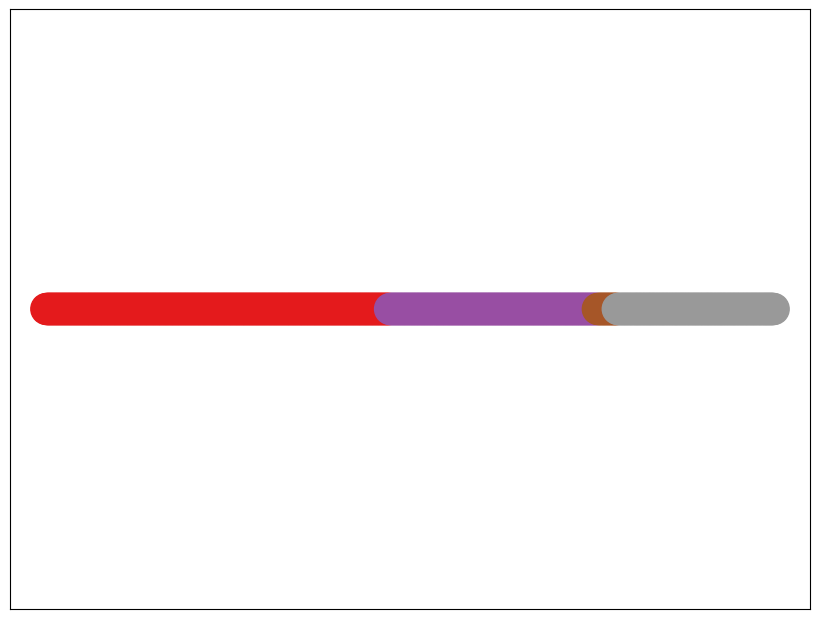

In [59]:
def plot_graph(graph: dgl.DGLGraph):

    """
    Plots the graph with nodes having the same label in the same color.

    graph: A DGLGraph to plot.
    """

    # Convert to NetworkX graph for visualization
    nx_graph = graph.to_networkx()

    # Extract labels
    labels = graph.ndata['label'].numpy()

    # Assign colors based on labels
    unique_labels = set(labels)
    color_map = {label: idx for idx, label in enumerate(unique_labels)}
    node_colors = [color_map[label] for label in labels]

    # Plot the graph
    plt.figure(figsize=(8, 6))
    pos = graph.ndata['pos']
    nx.draw(
        nx_graph,
        pos,
        #with_labels=True,
        node_color=node_colors,
        cmap=plt.cm.Set1,
        node_size=500,
        font_size=10,
        font_color='white'
    )
    plt.title("Graph with Node Labels as Colors")
    plt.show()

# Plot the graph
plot_graph(graph)


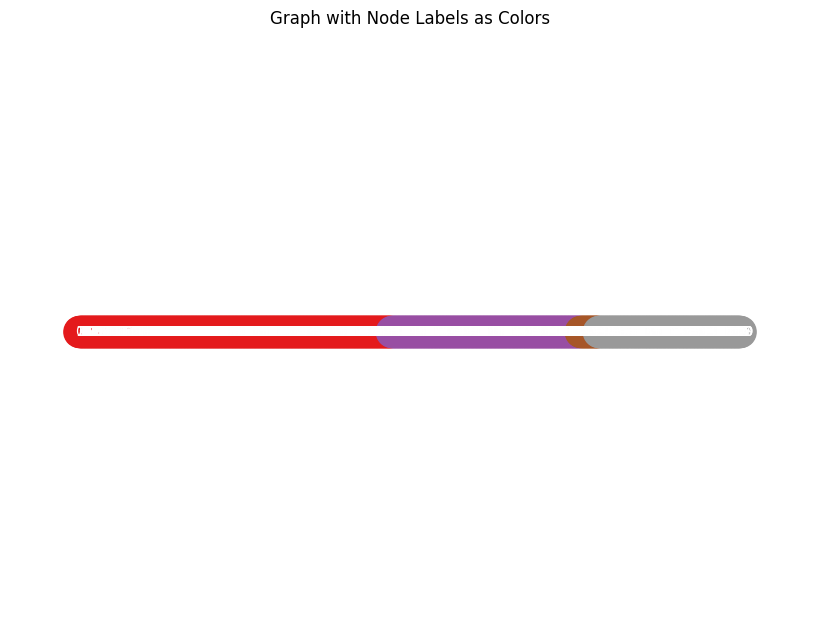

In [43]:
def plot_graph(graph):
    """
    Plots the graph with nodes having the same label in the same color.

    graph: A DGLGraph to plot.
    """
    import matplotlib.pyplot as plt
    import networkx as nx

    # Convert to NetworkX graph for visualization
    nx_graph = graph.to_networkx()

    # Extract labels
    labels = graph.ndata['label'].numpy()

    # Assign colors based on labels
    unique_labels = set(labels)
    color_map = {label: idx for idx, label in enumerate(unique_labels)}
    node_colors = [color_map[label] for label in labels]

    # Ensure 2D positions for plotting
    pos = graph.ndata['pos'][:, :2]  # Take only the first two dimensions

    # Plot the graph
    plt.figure(figsize=(8, 6))
    nx.draw(
        nx_graph,
        pos=pos.numpy(),  # Convert tensor to numpy
        node_color=node_colors,
        with_labels=True,
        cmap=plt.cm.Set1,
        node_size=500,
        font_size=10,
        font_color="white",
    )
    plt.title("Graph with Node Labels as Colors")
    plt.show()

plot_graph(graph)


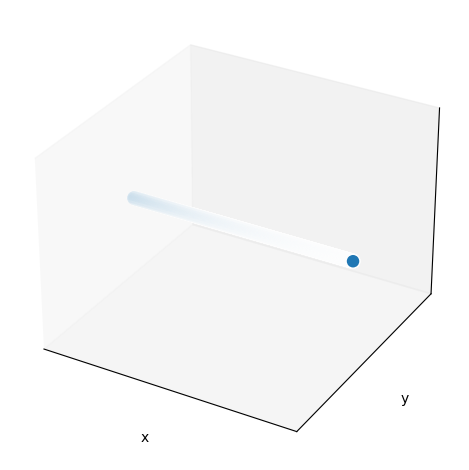

In [44]:
from mpl_toolkits.mplot3d import Axes3D

# The graph to visualize
G = graph.to_networkx()

# 3d spring layout
pos = graph.ndata['pos']
# Extract node and edge positions from the layout
node_xyz = np.array([pos[v] for v in sorted(G)])
edge_xyz = np.array([(pos[u], pos[v]) for u, v in G.edges()])

# Create the 3D figure
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

# Plot the nodes - alpha is scaled by "depth" automatically
ax.scatter(*node_xyz.T, s=100, ec="w")

# Plot the edges
for vizedge in edge_xyz:
    ax.plot(*vizedge.T, color="tab:gray")


def _format_axes(ax):
    """Visualization options for the 3D axes."""
    # Turn gridlines off
    ax.grid(False)
    # Suppress tick labels
    for dim in (ax.xaxis, ax.yaxis, ax.zaxis):
        dim.set_ticks([])
    # Set axes labels
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")


_format_axes(ax)
fig.tight_layout()
plt.show()

In [45]:
#!pip install --upgrade pyvista
import pyvista as pv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 77.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 633.2/633.2 kB 25.4 MB/s  0:00:00
  Attempting uninstall: pyvistam╺━━━━━━━━━━━━━━━━━━━ 2/4 [cyclopts]
    Found existing installation: pyvista 0.39.0━━━━━━━━━━━━━━━ 2/4 [cyclopts]
    Uninstalling pyvista-0.39.0:m╺━━━━━━━━━━━━━━━━━━━ 2/4 [cyclopts]
      Successfully uninstalled pyvista-0.39.0━━━━━━━━━━━━━━━━━ 2/4 [cyclopts]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pyvista]m3/4 [pyvista]

[notice] A new release of pip is available: 25.3 -> 26.1
[notice] To update, run: pip install --upgrade pip


In [46]:
# Extraction des points
points = df_wgr.iloc[:, 1:4].values

# Vérification des dimensions
print("Shape of points:", points.shape)

# Création de l'objet PolyData
point_cloud = pv.PolyData(points)

# Vérification des dimensions des tableaux avant l'affectation
labels = graph.ndata['label'].numpy()
gr_values = df_wgr.iloc[:, 0].values

print("Shape of labels:", labels.shape)
print("Shape of gr_values:", gr_values.shape)

# S'assurer que les dimensions correspondent
if labels.shape[0] == points.shape[0]:
    point_cloud["label"] = labels
else:
    print("Dimension mismatch: labels")

if gr_values.shape[0] == points.shape[0]:
    point_cloud["gr"] = gr_values
else:
    print("Dimension mismatch: gr_values")

# Vérification du PolyData
print(point_cloud)

Shape of points: (841, 3)
Shape of labels: (841,)
Shape of gr_values: (841,)
PolyData (0x7f8cae6e0d00)
  N Cells:    841
  N Points:   841
  N Strips:   0
  X Bounds:   6.001e+03, 6.841e+03
  Y Bounds:   4.867e+01, 4.867e+01
  Z Bounds:   2.145e+00, 2.145e+00
  N Arrays:   2


In [47]:
print(df_tops.columns)  # Vérifie si 'wellName' existe
print(df_tops.head())  # Affiche les premières lignes


Index(['NIOBARA', 'CODELL', 'FORT_HAYS'], dtype='object')
             NIOBARA  CODELL  FORT_HAYS
well_name                              
512320698.0   6398.0  6638.0     6661.0
512320699.0   6407.0  6656.0     6676.0
512320928.0   6520.0  6746.0     6793.0
512320970.0   6544.0  6770.0     6816.0
512320971.0   6510.0  6742.0     6789.0


In [63]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
import dgl
import dgl.nn.pytorch as dglnn
import torch.nn.functional as F
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report
import matplotlib.colors as colors

In [64]:
def step_function(start_depth, end_depth, tops_depth):
    if not tops_depth or start_depth >= end_depth:
        return [(start_depth, 1)]
    step_values = []
    current_value = 1
    for depth in range(start_depth + 1, end_depth + 1):
        if depth in tops_depth:
            current_value += 1
        step_values.append((depth, current_value))
    #creation labels
    return step_values

In [65]:
class WellGraphDataset(Dataset):
    def __init__(self, df_log, df_tops, input_variable, start_depth=start_depth, max_wells=3):
        self.df_log = df_log
        self.df_tops = df_tops
        self.input_variable = input_variable
        self.start_depth = start_depth
        self.well_names = df_log['wellName'].unique()[:max_wells]
        self.fallback_tops = df_tops.median().tolist()  # or .mean().tolist()

    def __len__(self):
        return len(self.well_names)

    def __getitem__(self, idx):
        well = self.well_names[idx]
        start_time = time.time()
        if well not in self.df_log['wellName'].values:
            return dgl.graph(([], []))
        #filtre
        df_wgr = Well_grlog_cleaning(well, self.df_log, self.input_variable)
        df_wgr = df_wgr[df_wgr['Depth'] > self.start_depth]
        if df_wgr.empty:
            return dgl.graph(([], []))
        tops_list = self.df_tops.loc[well].dropna().tolist() if well in self.df_tops.index else []
        end_depth = df_wgr['Depth'].max()
        #labelise
        labels = step_function(self.start_depth, end_depth, sorted(tops_list))
        if time.time() - start_time > 10:
            return dgl.graph(([], []))
        #creation du graph
        graph = create_graph(df_wgr, labels)
        if graph.num_nodes() == 0:
            #ajoute un noeud si aucun noeud présent
            graph.add_nodes(1)
            graph.ndata['features'] = torch.zeros(1, len(self.input_variable), dtype=torch.float32)
            graph.ndata['pos'] = torch.zeros(1, 3, dtype=torch.float32)
            graph.ndata['label'] = torch.tensor([0], dtype=torch.int64)
        return graph

def collate_graphs(samples):
    valid_graphs = [g for g in samples if g.num_nodes() > 0]
    if len(valid_graphs) == 0:
        return dgl.graph(([], []))
    #aggrege les graphes pour le dataloader
    return dgl.batch(valid_graphs)

In [66]:
class WellGraphDataset(Dataset):
    def __init__(self, df_log, df_tops, input_variable, start_depth=6000, max_wells=200):
        self.df_log = df_log
        self.df_tops = df_tops
        self.input_variable = input_variable
        self.start_depth = start_depth
        # self.well_names = df_log['wellName'].unique()[:max_wells]
        well_list=df_log['wellName'].unique().astype(int)
        well_list=set(list(df_tops.index)).intersection(set(well_list))
        well_list=list(well_list)
        self.well_names = well_list[:max_wells]
    def __len__(self):
        return len(self.well_names)

    def __getitem__(self, idx):
        well = self.well_names[idx]
        start_time = time.time()
        if well not in self.df_tops.index:  ### change the condition
            return dgl.graph(([], []))
        df_wgr = Well_grlog_cleaning(well, self.df_log, self.input_variable)
        df_wgr = df_wgr[df_wgr['Depth'] > self.start_depth]
        if df_wgr.empty:
            return dgl.graph(([], []))
        tops_list = self.df_tops.loc[well].dropna().tolist() if well in self.df_tops.index else []
        end_depth = df_wgr['Depth'].max()
        labels = step_function(self.start_depth, end_depth, sorted(tops_list))
        if time.time() - start_time > 10:
            return dgl.graph(([], []))
        graph = create_graph(df_wgr, labels)
        if graph.num_nodes() == 0:
            graph.add_nodes(1)
            graph.ndata['features'] = torch.zeros(1, len(self.input_variable), dtype=torch.float32)
            graph.ndata['pos'] = torch.zeros(1, 3, dtype=torch.float32)
            graph.ndata['label'] = torch.tensor([0], dtype=torch.int64)
        return graph

In [67]:
"""MODEL"""
class ImprovedGNN(torch.nn.Module):
    def __init__(self, in_feats, hidden_sizes, n_classes, dropout=0.1):
        """
        Construit un modèle GNN composé de plusieurs couches GraphConv.
        Chaque couche est suivie d'une Batch Normalization, d'une activation LeakyReLU
        et d'un dropout pour améliorer la stabilité de l'entraînement.
        """
        super(ImprovedGNN, self).__init__()
        self.convs = torch.nn.ModuleList()
        self.bns = torch.nn.ModuleList()
        prev_size = in_feats
        for h in hidden_sizes:
            #Creation des couches : Graph Conv, Batch Normalisation
            self.convs.append(dglnn.GraphConv(prev_size, h))
            self.bns.append(torch.nn.BatchNorm1d(h))
            prev_size = h
        self.fc = torch.nn.Linear(prev_size, n_classes)
        #Couche linéaire pour terminer
        self.dropout = torch.nn.Dropout(dropout)
        #activation
        self.activation = F.leaky_relu

    def forward(self, g, features):
        h = features
        for conv, bn in zip(self.convs, self.bns):
            #Pour chaque couche, applique la convolution sur le graphe, la normalisation, l'activation et le dropout
            h = conv(g, h)
            h = bn(h)
            h = self.activation(h)
            h = self.dropout(h)
        out = self.fc(h)
        return out
    
    import dgl


class ExtendedGCNRegression(nn.Module):
    def __init__(self, in_feats, h_feats, dropout):
        super(ExtendedGCNRegression, self).__init__()
        self.gcn1 = dgl.nn.GraphConv(in_feats, h_feats)
        self.gcn2 = dgl.nn.GraphConv(h_feats, h_feats)
        self.linear = nn.Linear(h_feats, h_feats)  # Linear layer after 2nd GCN layer
        self.gcn3 = dgl.nn.GraphConv(h_feats, h_feats)
        self.gcn4 = dgl.nn.GraphConv(h_feats, 1)  # Output a single continuous value
        self.dropout = nn.Dropout(dropout)
        self.norm1 = nn.BatchNorm1d(h_feats)
        self.norm2 = nn.BatchNorm1d(h_feats)
        self.norm3 = nn.BatchNorm1d(h_feats)

    def forward(self, g, in_feat):
        h = self.gcn1(g, in_feat)
        h = F.relu(h)
        h = self.norm1(h)
        h = self.dropout(h)
        
        h = self.gcn2(g, h)
        h = F.relu(h)
        h = self.norm2(h)
        h = self.dropout(h)
        
        h = self.linear(h)  # Apply linear transformation
        h = F.relu(h)
        
        h = self.gcn3(g, h)
        h = F.relu(h)
        h = self.norm3(h)
        h = self.dropout(h)
        
        h = self.gcn4(g, h)
        return h

In [68]:

class GAT(nn.Module):
    def __init__(self, in_feats, h_feats, num_classes, num_heads):
        super(GAT, self).__init__()
        self.gat1 = dgl.nn.GATConv(in_feats, h_feats, num_heads)
        self.gat2 = dgl.nn.GATConv(h_feats * num_heads, num_classes, 1)

    def forward(self, g, in_feat):
        h = self.gat1(g, in_feat)
        h = F.elu(h)
        h = h.view(h.size(0), -1)  # Flatten the output
        h = self.gat2(g, h)
        return h

    
class ExtendedGAT(nn.Module):
    def __init__(self, in_feats, h_feats, num_classes, num_heads, dropout):
        super(ExtendedGAT, self).__init__()
        self.gat1 = dgl.nn.GATConv(in_feats, h_feats, num_heads)
        self.gat2 = dgl.nn.GATConv(h_feats * num_heads, h_feats, num_heads)
        self.gat3 = dgl.nn.GATConv(h_feats * num_heads, h_feats, num_heads)
        self.dropout = nn.Dropout(dropout)
        self.norm1 = nn.BatchNorm1d(h_feats * num_heads)
        self.norm2 = nn.BatchNorm1d(h_feats * num_heads)
        self.fc = nn.Linear(h_feats * num_heads, num_classes)

    def forward(self, g, in_feat):
        h = self.gat1(g, in_feat)
        h = F.elu(h)
        h = self.norm1(h.view(h.size(0), -1))  # Flatten and normalize
        h = self.dropout(h)
        h = self.gat2(g, h)
        h = F.elu(h)
        h = self.norm2(h.view(h.size(0), -1))  # Flatten and normalize
        h = self.dropout(h)
        h = self.gat3(g, h)
        h = F.elu(h)
        h = self.dropout(h)
        h = h.view(h.size(0), -1)  # Flatten the output
        h = self.fc(h)
        return h

In [69]:

class GraphSAGE(nn.Module):
    def __init__(self, in_feats, h_feats, num_classes):
        super(GraphSAGE, self).__init__()
        self.sage1 = dgl.nn.SAGEConv(in_feats, h_feats, 'mean')
        self.sage2 = dgl.nn.SAGEConv(h_feats, num_classes, 'mean')

    def forward(self, g, in_feat):
        h = self.sage1(g, in_feat)
        h = F.relu(h)
        h = self.sage2(g, h)
        return h


class ExtendedGraphSAGE(nn.Module):
    def __init__(self, in_feats, h_feats, num_classes, dropout):
        super(ExtendedGraphSAGE, self).__init__()
        self.sage1 = dgl.nn.SAGEConv(in_feats, h_feats, 'mean')
        self.linear = nn.Linear(h_feats, h_feats)
        self.sage2 = dgl.nn.SAGEConv(h_feats, h_feats, 'mean')
        self.sage3 = dgl.nn.SAGEConv(h_feats, num_classes, 'mean')
        self.dropout = nn.Dropout(dropout)
        self.norm1 = nn.BatchNorm1d(h_feats)
        self.norm2 = nn.BatchNorm1d(h_feats)

    def forward(self, g, in_feat):
        h = self.sage1(g, in_feat)
        h = F.relu(h)
        h = self.norm1(h)
        h = self.dropout(h)
        h = self.linear(h)  # Apply linear transformation
        h = F.relu(h)
        h = self.sage2(g, h)
        h = F.relu(h)
        h = self.norm2(h)
        h = self.dropout(h)
        h = self.sage3(g, h)
        return h

In [70]:
#Regression model that predicts the number than a classification 

class ExtendedGCNRegression(nn.Module):
    def __init__(self, in_feats, h_feats, dropout):
        super(ExtendedGCNRegression, self).__init__()
        self.gcn1 = dgl.nn.GraphConv(in_feats, h_feats)
        self.gcn2 = dgl.nn.GraphConv(h_feats, h_feats)
        self.linear1 = nn.Linear(h_feats, h_feats)  # Linear layer after 2nd GCN layer
        self.gcn3 = dgl.nn.GraphConv(h_feats, h_feats)
        self.gcn4 = dgl.nn.GraphConv(h_feats, h_feats)
        self.linear2 = nn.Linear(h_feats, 1)  # Final linear layer for output
        self.dropout = nn.Dropout(dropout)
        self.norm1 = nn.BatchNorm1d(h_feats)
        self.norm2 = nn.BatchNorm1d(h_feats)
        self.norm3 = nn.BatchNorm1d(h_feats)

    def forward(self, g, in_feat):
        h = self.gcn1(g, in_feat)
        h = F.relu(h)
        h = h.view(h.size(0), -1)  # Flatten the output
        h = self.norm1(h)
        h = self.dropout(h)
        
        h = self.gcn2(g, h)
        h = F.relu(h)
        h = h.view(h.size(0), -1)  # Flatten the output
        h = self.norm2(h)
        h = self.dropout(h)
        
        h = self.linear1(h)  # Apply linear transformation
        h = F.relu(h)
        
        h = self.gcn3(g, h)
        h = F.relu(h)
        h = h.view(h.size(0), -1)  # Flatten the output
        h = self.norm3(h)
        h = self.dropout(h)
        
        h = self.gcn4(g, h)
        h = F.relu(h)
        
        h = self.linear2(h)  # Final linear layer for output
        return h
    

# Loss and optimizer needs to be changed to MSE as it is a regression
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [53]:
"""FOCAL LOSS & POST TRAITEMENT"""
def focal_loss(pred, target, gamma=1, alpha=None, reduction="mean"):
    ce_loss = F.cross_entropy(pred, target, reduction="none", weight=alpha)
    pt = torch.exp(-ce_loss)
    focal_loss_val = ((1 - pt) ** gamma) * ce_loss
    if reduction == "mean":
        return focal_loss_val.mean()
    elif reduction == "sum":
        return focal_loss_val.sum()
    else:
        return focal_loss_val


def post_process_predictions(preds, window_size=5):
    #Filtrage median pour le traitement 
    processed_preds = preds.copy()
    for i in range(len(preds)):
        start = max(0, i - window_size // 2)
        end = min(len(preds), i + window_size // 2 + 1)
        processed_preds[i] = np.median(preds[start:end])
    return processed_preds.astype(int)

In [54]:
"""TRAINING"""
def train_gnn(model, train_dataloader, optimizer, criterion, scheduler, n_classes, epochs=50):
    model.train()
    #Set les loss
    loss_history = []
    accuracy_history = []
    precision_history = []
    recall_history = []
    f1_history = []

    for epoch in range(epochs):
        #Set par epoch
        total_loss = 0.0
        all_preds, all_labels = [], []

        train_batches = []
        test_batch = None

        for i, batch in enumerate(train_dataloader):
            if i < 4:
                train_batches.append(batch)
            elif i == 4:
                test_batch = batch
                break

        for batch_graphs in train_dataloader:
            # Ajoute des self-loops pour améliorer la propagation des messages
            batch_graphs = dgl.add_self_loop(batch_graphs)
            optimizer.zero_grad()
            features = batch_graphs.ndata['features']
            labels = batch_graphs.ndata['label']
            labels_adjusted = torch.clamp(labels - 1, 0, n_classes - 1) #Ajuste les labels sur l'échelle 0- 3 plutôt que 1 - 4
            pred = model(batch_graphs, features)
            loss = criterion(pred, labels_adjusted)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            preds = pred.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels_adjusted.cpu().numpy())
        #Calcul de la loss moyenne et des metrics
        avg_loss = total_loss / len(train_dataloader) 
        accuracy = accuracy_score(all_labels, all_preds)
        precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
        recall = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
        f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)
        loss_history.append(avg_loss)
        accuracy_history.append(accuracy)
        precision_history.append(precision)
        recall_history.append(recall)
        f1_history.append(f1)
        print(f'Epoch {epoch+1}/{epochs} → Loss: {avg_loss:.4f}, Accuracy: {accuracy:.4f}, '
              f'Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}')
        scheduler.step()

In [55]:
dataset = WellGraphDataset(df_log, df_tops, input_variable, max_wells=5)
dataloader = DataLoader(dataset, batch_size=2, shuffle=True, collate_fn=collate_graphs)

In [60]:
in_features = len(input_variable)
hidden_sizes = [128, 256, 256, 128, 64] #HiddenSize
n_classes = len(df_tops.columns) + 1
supports = torch.tensor([916, 466, 70, 382], dtype=torch.float32)
max_support = supports.max()
computed_weights = max_support / supports 

# Instanciation du modèle, définition de la fonction de perte, de l'optimiseur et du scheduler
model = ImprovedGNN(in_features, hidden_sizes, n_classes, dropout=0.1)
criterion = torch.nn.CrossEntropyLoss(weight=computed_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.5)#Cyclic LR ,fitonecyle, cycliclr

# Entraînement du modèle
train_gnn(model, dataloader, optimizer, criterion, scheduler, n_classes, epochs=120)

/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (
/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (
/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be 

📢 Epoch 1/120 → Loss: 1.0971, Accuracy: 0.3577, Precision: 0.6682, Recall: 0.3577, F1: 0.4291


/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (
/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (
/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be 

📢 Epoch 2/120 → Loss: 0.7245, Accuracy: 0.7684, Precision: 0.8219, Recall: 0.7684, F1: 0.7791


/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (
/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (
/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be 

📢 Epoch 3/120 → Loss: 0.6098, Accuracy: 0.7774, Precision: 0.8206, Recall: 0.7774, F1: 0.7875


... (23 outputs left out)

📢 Epoch 15/120 → Loss: 0.4612, Accuracy: 0.7890, Precision: 0.8140, Recall: 0.7890, F1: 0.7949


/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (
/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (
/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be 

📢 Epoch 16/120 → Loss: 0.4217, Accuracy: 0.7953, Precision: 0.8241, Recall: 0.7953, F1: 0.8017


KeyboardInterrupt: 

/opt/conda/lib/python3.10/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (



 Évaluation sur le batch de test (Prédictions Brutes):
   Accuracy : 0.4894
   Precision: 0.5446
   Recall   : 0.4894
   F1 Score : 0.4015

Rapport de classification (Brutes) :
              precision    recall  f1-score   support

           0       0.57      1.00      0.73       527
           1       0.23      0.09      0.13       463
           2       0.24      1.00      0.39        49
           3       1.00      0.15      0.27       326

    accuracy                           0.49      1365
   macro avg       0.51      0.56      0.38      1365
weighted avg       0.54      0.49      0.40      1365



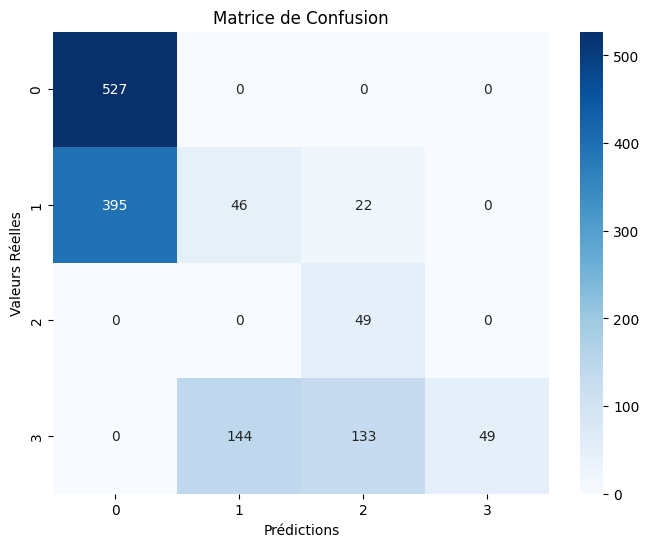


📢 Évaluation sur le batch de test (Prédictions Post-traitées):
   Accuracy : 0.4916
   Precision: 0.5502
   Recall   : 0.4916
   F1 Score : 0.4049

Rapport de classification (Post-traitées) :
              precision    recall  f1-score   support

           0       0.57      1.00      0.73       527
           1       0.24      0.10      0.14       463
           2       0.24      1.00      0.39        49
           3       1.00      0.15      0.26       326

    accuracy                           0.49      1365
   macro avg       0.51      0.56      0.38      1365
weighted avg       0.55      0.49      0.40      1365



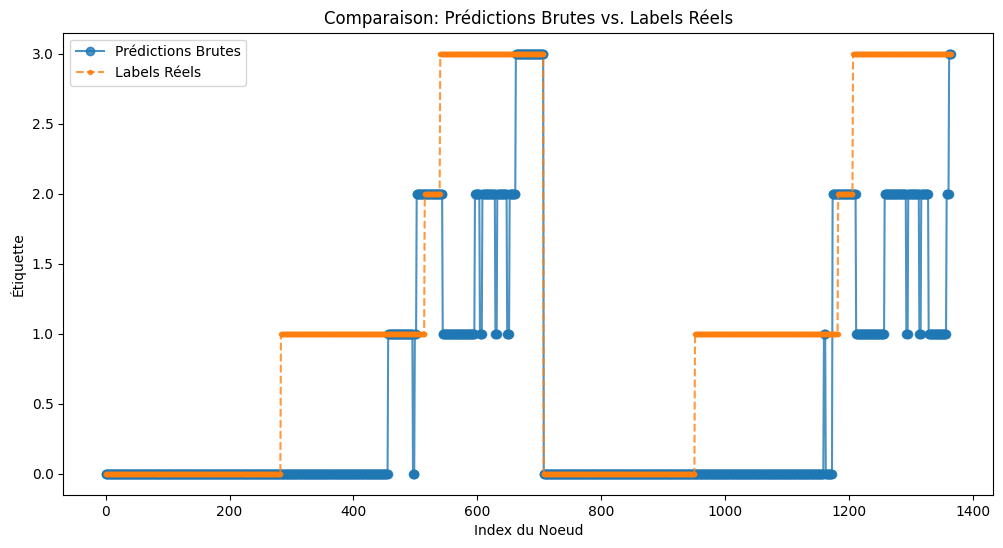

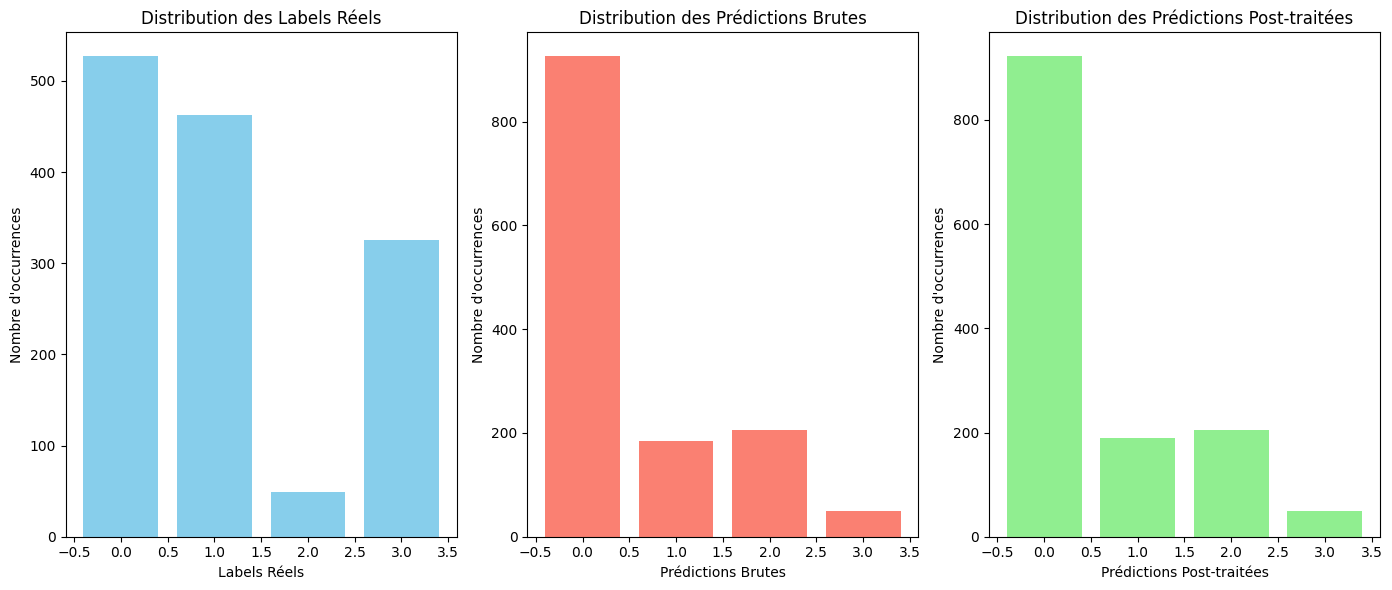

In [61]:
model.eval()
with torch.no_grad():
    batch = next(iter(dataloader))
    batch = dgl.add_self_loop(batch)
    #Raw preds
    raw_preds = model(batch, batch.ndata['features']).argmax(dim=1).cpu().numpy()
    labels = batch.ndata['label'].cpu().numpy()
    labels_adjusted = np.clip(labels-1, 0, n_classes - 1)
    #On ajuste les labels comme pour le training
    #metrics
    test_accuracy = accuracy_score(labels_adjusted, raw_preds)
    test_precision = precision_score(labels_adjusted, raw_preds, average='weighted', zero_division=0)
    test_recall = recall_score(labels_adjusted, raw_preds, average='weighted', zero_division=0)
    test_f1 = f1_score(labels_adjusted, raw_preds, average='weighted', zero_division=0)

    print("\n Évaluation sur le batch de test (Prédictions Brutes):")
    print(f"   Accuracy : {test_accuracy:.4f}")
    print(f"   Precision: {test_precision:.4f}")
    print(f"   Recall   : {test_recall:.4f}")
    print(f"   F1 Score : {test_f1:.4f}")
    print("\nRapport de classification (Brutes) :")
    print(classification_report(labels_adjusted, raw_preds, zero_division=0))
    # Application du post-processing
    processed_preds = post_process_predictions(raw_preds, window_size=5)
    # Confusion Matrix
    cm_raw = confusion_matrix(labels_adjusted, processed_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_raw, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Prédictions")
    plt.ylabel("Valeurs Réelles")
    plt.title("Matrice de Confusion")
    plt.show()

    # Calcul des métriques post traitement
    proc_accuracy = accuracy_score(labels_adjusted, processed_preds)
    proc_precision = precision_score(labels_adjusted, processed_preds, average='weighted', zero_division=0)
    proc_recall = recall_score(labels_adjusted, processed_preds, average='weighted', zero_division=0)
    proc_f1 = f1_score(labels_adjusted, processed_preds, average='weighted', zero_division=0)

    print("\n📢 Évaluation sur le batch de test (Prédictions Post-traitées):")
    print(f"   Accuracy : {proc_accuracy:.4f}")
    print(f"   Precision: {proc_precision:.4f}")
    print(f"   Recall   : {proc_recall:.4f}")
    print(f"   F1 Score : {proc_f1:.4f}")
    print("\nRapport de classification (Post-traitées) :")
    print(classification_report(labels_adjusted, processed_preds, zero_division=0))

    
    # Graphique 1 : Comparaison des prédictions et  réels
    
    plt.figure(figsize=(12, 6))
    plt.plot(processed_preds, label="Prédictions Brutes", marker='o', linestyle='-', alpha=0.8)
    plt.plot(labels_adjusted, label="Labels Réels", marker='.', linestyle='--', alpha=0.8)
    plt.xlabel("Index du Noeud")
    plt.ylabel("Étiquette")
    plt.title("Comparaison: Prédictions Brutes vs. Labels Réels")
    plt.legend()
    plt.show()

    
    # Graphique 2 : Histogrammes de distrib
    
    plt.figure(figsize=(14, 6))
    plt.subplot(1, 3, 1)
    unique_actual, counts_actual = np.unique(labels_adjusted, return_counts=True)
    plt.bar(unique_actual, counts_actual, color='skyblue')
    plt.xlabel("Labels Réels")
    plt.ylabel("Nombre d'occurrences")
    plt.title("Distribution des Labels Réels")

    plt.subplot(1, 3, 2)
    unique_raw, counts_raw = np.unique(raw_preds, return_counts=True)
    plt.bar(unique_raw, counts_raw, color='salmon')
    plt.xlabel("Prédictions Brutes")
    plt.ylabel("Nombre d'occurrences")
    plt.title("Distribution des Prédictions Brutes")

    plt.subplot(1, 3, 3)
    unique_proc, counts_proc = np.unique(processed_preds, return_counts=True)
    plt.bar(unique_proc, counts_proc, color='lightgreen')
    plt.xlabel("Prédictions Post-traitées")
    plt.ylabel("Nombre d'occurrences")
    plt.title("Distribution des Prédictions Post-traitées")

    plt.tight_layout()
    plt.show()

In [54]:
def plot_well_side_by_side(df_well, actual_labels, predicted_labels, well_name=None):
    #GR et Depth comme dans l'exemple
    gr = np.array(df_well['GR'])
    depth = np.array(df_well['Depth'])
    
    actual_labels = np.array(actual_labels)
    predicted_labels = np.array(predicted_labels)
    
    boundaries = np.arange(0.5, 5.5, 1) 
    norm = colors.BoundaryNorm(boundaries, ncolors=10)
    
    # 2 plot : Actuals vs Predicted
    fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
    
    sc1 = axes[0].scatter(gr, depth, c=actual_labels, cmap='tab10', s=20, norm=norm)
    axes[0].invert_yaxis()
    axes[0].set_xlabel("GR")
    axes[0].set_ylabel("Depth (ft)")
    axes[0].set_title(f"Actual Marker Labels\n{well_name}" if well_name else "Actual Marker Labels")
    
    sc2 = axes[1].scatter(gr, depth, c=predicted_labels, cmap='tab10', s=20, norm=norm)
    axes[1].invert_yaxis()
    axes[1].set_xlabel("GR")
    axes[1].set_title("Predicted Marker Labels")
    
    # Legende : colorbar
    fig.subplots_adjust(right=0.8)
    cbar_ax = fig.add_axes([0.85, 0.15, 0.03, 0.7])
    cbar = fig.colorbar(sc2, cax=cbar_ax, ticks=[1, 2, 3, 4])
    cbar.set_label("Marker Label")
    
    plt.tight_layout(rect=[0, 0, 0.82, 1])
    plt.show()

In [55]:
def plot_well_from_name(well, df_log, df_tops, input_variable, model):
    #Initialise les données
    df_wgr = Well_grlog_cleaning(well, df_log, input_variable)
    df_wgr = df_wgr[df_wgr['Depth'] > start_depth]
    df_wgr = df_wgr.dropna(subset=['Depth'])
    if df_wgr.empty:
        print(f"No valid depth data for well {well}")
        return

    if well in df_tops.index:
        tops_list = df_tops.loc[well].dropna().tolist()
    else:
        tops_list = []
    end_depth = int(df_wgr['Depth'].max())
    step_vals = step_function(start_depth, end_depth, sorted(tops_list))

    #Creation du graphe
    graph = create_graph(df_wgr, step_vals)
    graph = dgl.add_self_loop(graph)

    #Récupère les labels
    actual_labels = graph.ndata['label'].cpu().numpy()

    #Run le model
    model.eval()
    with torch.no_grad():
        preds = model(graph, graph.ndata['features'])
        predicted_labels = preds.argmax(dim=1).cpu().numpy()
        predicted_labels = post_process_predictions(predicted_labels, window_size=5)
        predicted_labels = predicted_labels+1

    #Plot
    plot_well_side_by_side(df_wgr, actual_labels, predicted_labels, well_name=well)


c:\Users\Alexa\OneDrive\Desktop\CRP\env\lib\site-packages\dgl\backend\pytorch\tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (
C:\Users\Alexa\AppData\Local\Temp\ipykernel_5972\2319886279.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.82, 1])


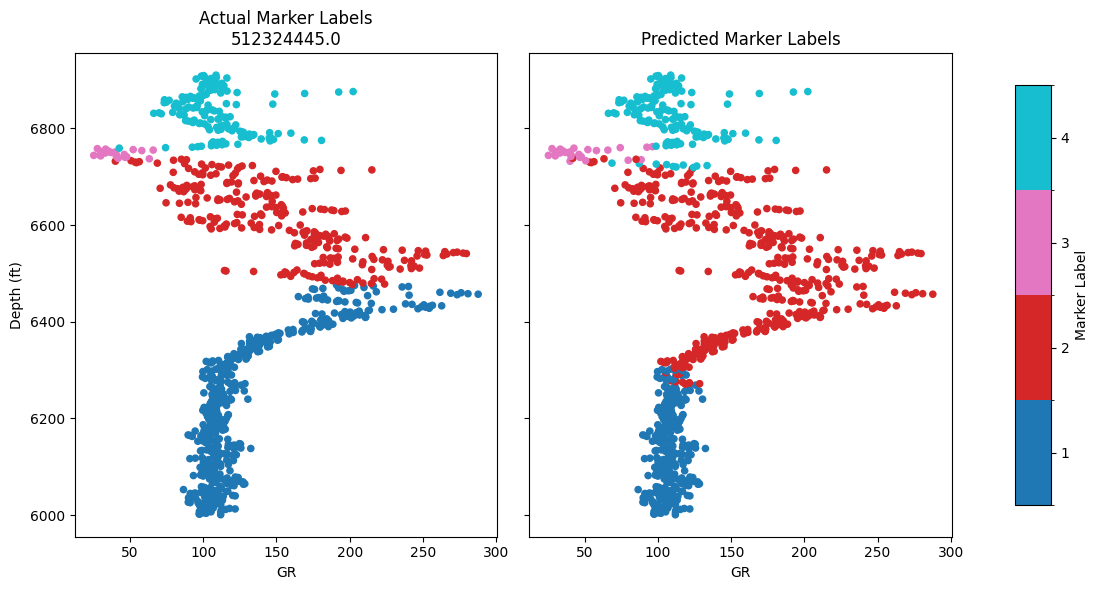

In [56]:
plot_well_from_name(well, df_log, df_tops, ['GR', 'Depth', 'Latitude', 'Longitude'], model)

In [57]:
#picking the first and last occurences of the elemet in the array

# Function to find starting and end index
def findIndex (a, n, key ):
    start = -1

    # Traverse from beginning to find
    # first occurrence
    for i in range(n):
        if a[i] == key:
            start = i
            break

    # Traverse from end to find last
    # occurrence.
    end = start
    if start > 0:
        for i in range(n-1, start - 1, -1):
            if a[i] == key:
                end = i
                break

    #print(start, end)
    return (start, end)
# def predicted_marker_depth(pred_array, depth_array, con):
#     """
#     Generates the step function values if start_time < times[0] < times[1] < ... < times[-1] < end_time.
#     Function input:
#     - pred_array: The array of predicted labels.
#     - depth_array: The array of depths.
#     - con: Condition for picking the first or last occurence.

#     Output: A tuple representing the marker depths.
#     """

#     arr = pred_array
#     n = len(arr)

#     if con == 'first':
#         i = 0
#         M_idx = findIndex(arr, n, 2)
#         S_idx = findIndex(arr, n, 3)
#         C_idx = findIndex(arr, n, 4)

#     elif con == 'last':
#         i = 1  # Picking the last occurrence (end index)
#         M_idx = findIndex(arr, n, 1)  # Note that these are using different labels than 'first'
#         S_idx = findIndex(arr, n, 2)
#         C_idx = findIndex(arr, n, 3)

#     else:
#         print('Please specify the correct condition as strings: \n a. first \n b. last')
#         return (None, None, None)  # Return None if con is invalid

#     # Check if marker indices are valid before accessing depth_array
#     M_depth = depth_array[M_idx[i]] if M_idx[i] != -1 and M_idx[i] < len(depth_array) else None
#     S_depth = depth_array[S_idx[i]] if S_idx[i] != -1 and S_idx[i] < len(depth_array) else None
#     C_depth = depth_array[C_idx[i]] if C_idx[i] != -1 and C_idx[i] < len(depth_array) else None

#     return (M_depth, S_depth, C_depth)
def predicted_marker_depth( pred_array, depth_array, con):

    arr = pred_array
    n = len(arr)
    if con == 'first':
        i = 0
        M_idx = findIndex(arr, n, 2)
        S_idx = findIndex(arr, n, 3)
        C_idx = findIndex(arr, n, 4)

    elif con == 'last':
        i = 1
        M_idx = findIndex(arr, n, 1)
        S_idx = findIndex(arr, n, 2)
        C_idx = findIndex(arr, n, 3)

    else: print('Please specify the correct condition as strings: \n a. first \n b. last' )

    M_depth = depth_array[M_idx[i]]
    S_depth = depth_array[S_idx[i]]
    C_depth = depth_array[C_idx[i]]

    # M_depth = depth[M_idx[i]]


    return (M_depth, C_depth, S_depth)

In [58]:
def findIndex (a, n, key ):
    start = -1

    # Traverse from beginning to find
    # first occurrence
    for i in range(n):
        if a[i] == key:
            start = i
            break

    # Traverse from end to find last
    # occurrence.
    end = start
    if start > 0:
        for i in range(n-1, start - 1, -1):
            if a[i] == key:
                end = i
                break

    #print(start, end)
    return (start, end)

def predicted_marker_depth(pred_array, depth_array, con):
    arr = pred_array
    n = len(arr)
    if con == 'first':
        i = 0
        M_idx = findIndex(arr, n, 2)
        S_idx = findIndex(arr, n, 3)
        C_idx = findIndex(arr, n, 4)
    elif con == 'last':
        i = 1
        M_idx = findIndex(arr, n, 1)
        S_idx = findIndex(arr, n, 2)
        C_idx = findIndex(arr, n, 3)
    else:
        print('Please specify "first" or "last"')
        return (None, None, None)
    
    def safe_depth(idx_tuple):
        idx = idx_tuple[i]
        if idx == -1 or idx >= len(depth_array):
            return np.nan
        return depth_array[idx]
    
    M_depth = safe_depth(M_idx)
    S_depth = safe_depth(S_idx)
    C_depth = safe_depth(C_idx)
    
    return (M_depth, S_depth, C_depth)


In [59]:
# only top 200, change the index as you want
# create well_list to make sure the wells are at the same time in the file df_log and df_tops
well_list=df_log['wellName'].unique().astype(int)
well_list=set(list(df_tops.index)).intersection(set(well_list))
well_list=list(well_list)

#dataset
dataset = WellGraphDataset(df_log, df_tops, input_variable, max_wells=200)
dataloader = DataLoader(dataset, batch_size=2, shuffle=True, collate_fn=collate_graphs)

#generate df preds
num_well=200
df_preds=pd.DataFrame(columns = ['wellName','MARCEL', 'CONRAD','SYLVAIN' ])
new_data=[]
for index in range(num_well):
  # generate the depth and labels of corresponding well
  well=well_list[index]
  start_depth=start_depth
  # step function
  df_wgr = Well_grlog_cleaning(well, df_log,input_variable)
  df_wgr = df_wgr[df_wgr['Depth'] > start_depth]
  tops_list = df_tops.loc[well].dropna().tolist()
  end_depth = df_wgr['Depth'].max()
  labels = step_function(start_depth, end_depth, sorted(tops_list)) #step_function的结果是对于每个深度，assign对应的marker label
  depth_array= [tup[0] for tup in labels]
  ##get preds
  model.eval()
  with torch.no_grad():
      batch = dataset[index]
      batch = dgl.add_self_loop(batch)
      preds = model(batch, batch.ndata['features']).argmax(dim=1).cpu().numpy()
      preds = post_process_predictions(preds, window_size=5)
      labels = batch.ndata['label'].cpu().numpy()
      labels_adjusted = np.clip(labels - 1, 0, n_classes - 1)
  pred_array=preds
  m_m,m_c,m_s=predicted_marker_depth(pred_array, depth_array, 'last')
  new_data.append([well, m_m, m_c, m_s])
df_preds=pd.DataFrame(new_data, columns = ['wellName','MARCEL','CONRAD', 'SYLVAIN'])
df_preds.head()

c:\Users\Alexa\OneDrive\Desktop\CRP\env\lib\site-packages\dgl\backend\pytorch\tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (
c:\Users\Alexa\OneDrive\Desktop\CRP\env\lib\site-packages\dgl\backend\pytorch\tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (
c:\Users\Alexa\OneDrive\Desktop\CRP\env\lib\site-packages\dgl\backend\pytorch\tensor.py:445: UserWarning: TypedStorage is deprecated. It wil

,wellName,MARCEL,CONRAD,SYLVAIN
0,512329746.0,6737,NaN,7089
1,512331798.0,6658,6502.0,6619
2,512325663.0,6715,6787.0,6961
3,512325664.0,6744,6809.0,6997
4,512331808.0,6702,6542.0,6707


In [60]:
## df actual

### garder only wells that could be found in df_log file
df_tops.reset_index(inplace=True)
df_tops_valide=df_tops[df_tops['wellName'].isin(well_list[:200])] #ATTENTION: should be the same well as df_preds
df_tops_valide.sort_values(by=['wellName'],inplace=True)
df_tops_valide.head()
df_tops_valide.set_index('wellName',inplace=True)
df_tops.set_index('wellName',inplace=True)
# df_tops_actual = df_tops.sort_values(by = ['wellName'])
# df_tops_actual = df_tops_actual.set_index('wellName')
# df_tops_actual.head()

C:\Users\Alexa\AppData\Local\Temp\ipykernel_5972\2120449443.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tops_valide.sort_values(by=['wellName'],inplace=True)


In [61]:
df_tops_valide

,MARCEL,CONRAD,SYLVAIN
wellName,,,
512322228.0,6390.0,6660.0,6614.0
512322230.0,6443.0,6714.0,6668.0
512322231.0,6509.0,6812.0,6752.0
512322233.0,6508.0,6776.0,6740.0
512322243.0,6340.0,6602.0,6559.0
...,...,...,...
512332568.0,6533.0,6839.0,6814.0
512334023.0,6288.0,6534.0,6510.0
512334042.0,6264.0,6524.0,6500.0


In [62]:
df_preds.set_index('wellName',inplace=True)
df_preds=df_preds.sort_index()
df_preds

,MARCEL,CONRAD,SYLVAIN
wellName,,,
512322228.0,6743,6662.0,6874
512322230.0,6725,6715.0,6927
512322231.0,6749,6812.0,7004
512322233.0,6714,6778.0,6976
512322243.0,6790,6609.0,6813
...,...,...,...
512332568.0,6729,6829.0,6990
512334023.0,6690,6535.0,6704
512334042.0,6748,NaN,7082


In [63]:
def recall_tops(df_tops_true, df_tops_pred, tolerance = 10):

    if set(df_tops_true.columns) == set(df_tops_pred.columns) :
        concat_df = df_tops_true.copy()
        for col in df_tops_pred.columns:
            concat_df[col+"_pred"] = df_tops_pred[col]
        tp = 0
        p = 0
        mae = 0
        for col in df_tops_true:
            diffname = "{0}_ae".format(col)
            tpname = "{0}_tp".format(col)
            p += concat_df[col].count()
            concat_df[diffname] = concat_df[col]-concat_df[str(col + "_pred")]
            concat_df[diffname] = concat_df[diffname].abs()
            concat_df[tpname] = concat_df[diffname] <= tolerance
            tp += concat_df[tpname].sum()
            mae += concat_df[diffname].sum()
        return tp/p, mae/p, concat_df
    else :
        print("the tops columns are not valid")
    return None,None,None

In [64]:
recall, mae, df_res = recall_tops(df_tops_valide,df_preds,tolerance = 20)
print("recall {0}, mae {1}".format(recall,mae))
df_res

recall 0.24166666666666667, mae 217.24


,MARCEL,CONRAD,SYLVAIN,MARCEL_pred,CONRAD_pred,SYLVAIN_pred,MARCEL_ae,MARCEL_tp,CONRAD_ae,CONRAD_tp,SYLVAIN_ae,SYLVAIN_tp
wellName,,,,,,,,,,,,
512322228.0,6390.0,6660.0,6614.0,6743,6662.0,6874,353.0,False,2.0,True,260.0,False
512322230.0,6443.0,6714.0,6668.0,6725,6715.0,6927,282.0,False,1.0,True,259.0,False
512322231.0,6509.0,6812.0,6752.0,6749,6812.0,7004,240.0,False,0.0,True,252.0,False
512322233.0,6508.0,6776.0,6740.0,6714,6778.0,6976,206.0,False,2.0,True,236.0,False
512322243.0,6340.0,6602.0,6559.0,6790,6609.0,6813,450.0,False,7.0,True,254.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...
512332568.0,6533.0,6839.0,6814.0,6729,6829.0,6990,196.0,False,10.0,True,176.0,False
512334023.0,6288.0,6534.0,6510.0,6690,6535.0,6704,402.0,False,1.0,True,194.0,False
512334042.0,6264.0,6524.0,6500.0,6748,NaN,7082,484.0,False,NaN,False,582.0,False
